# Reading the soil through overlapping electromagnetic kernels


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测到目标核查卡

当前存在 `data/raw_data.npz`；所述获取/估计路径由本地代码实现。

任务 `covercrop_electromagnetic_conductivity` 的观测定义：当前raw_data.npz的实际键、形状、dtype与README单位说明：apparent_conductivity (1, 30, 6) float64：Calibrated apparent conductivity, mS/m; station then coil；station_coordinates (1, 30, 3) float64：x, y, surface elevation, m; no geometric correction of the local response；coil_spacing (1, 6) float64：Transmitter-receiver separation, m；layer_interfaces (1, 6) float64：Fixed layer-bottom depths below local surface, m。恢复目标：30站点、7层土壤电导率剖面，mS/m。

获取模型：低感应数VCP/HCP累积灵敏度在层界差分后线性叠加层电导率。实际恢复算法：solvers.reconstruct逐站L-BFGS-B有界拟合加深度差分惩罚；quadratic_solution为比较。语义类型为 `inverse_spatial`；其中闭式逆也属于反问题，但内部制造观测或缺输入的限制见下文。

真值情况：数值方法参考，不能当作独立物理真值；test/validation.md:7为独立作者方法结果，不是实测土壤真值。评估方法参考与仪器校准均不能当作独立物理真值。

现有实验和图：covercrop_electromagnetic_conductivity.ipynb单元3有保存图；图内容由该单元调用的本地visualization函数生成；covercrop_electromagnetic_conductivity.ipynb单元5有保存图；图内容由该单元调用的本地visualization函数生成；covercrop_electromagnetic_conductivity.ipynb单元7有保存图；图内容由该单元调用的本地visualization函数生成；covercrop_electromagnetic_conductivity.ipynb单元8：5. Scientific comparisons and sensitivity；covercrop_electromagnetic_conductivity.ipynb单元9有保存图；图内容由该单元调用的本地visualization函数生成；covercrop_electromagnetic_conductivity.ipynb单元10有保存图；图内容由该单元调用的本地visualization函数生成；covercrop_electromagnetic_conductivity.ipynb单元11有保存图；图内容由该单元调用的本地visualization函数生成。图/比较代码位于单元3, 5, 7, 9, 10, 11（从0计数）。代码单元8个，带execution_count的8个，保存PNG输出6幅；本审计未重新运行。

现有输出来自历史执行；本次未复跑。

限制与缺口：本次为静态语义与证据核查，未重新验证数值正确性或运行结果。

<!-- inverse-evidence-audit:20261026:end -->


This maintainer notebook actively reconstructs all30 cover-crop transect stations from the bound calibrated field observations. The standard comparison is a fresh execution of the published EMagPy method, independently captured before local extraction. There is no independently measured conductivity truth. No station is removed.

## 1. Physical question

Time-varying coil fields induce electric currents in soil. Their secondary magnetic fields sample broad depth intervals. We seek a conductivity section, not a unique water-content or clay map. Different coil orientations provide complementary depth weighting. The working model assumes a nonmagnetic, locally horizontally layered half-space with ground-contact coils. Its limitations must remain visible in the residuals.

In [1]:
from pathlib import Path
import sys,time,json,os,platform
import numpy as np
import scipy,matplotlib
import matplotlib.pyplot as plt
root=Path.cwd()
if root.name=='notebooks': root=root.parent
sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.solvers import reconstruct,objective
from src import visualization as viz
data=load_data(root/'data/raw_data.npz')
with np.load(root/'notebooks/reference_outputs/upstream_measurements.npz',allow_pickle=False) as f:
    author=f['reconstruction'][0].copy();gn=f['gauss_newton'][0].copy()
numeric={}
print('ACTUAL_KERNEL_ENVIRONMENT',json.dumps({'executable':sys.executable,'python':sys.version,'os':platform.platform(),'numpy':np.__version__,'numpy_file':np.__file__,'scipy':scipy.__version__,'scipy_file':scipy.__file__,'matplotlib':matplotlib.__version__,'backend':matplotlib.get_backend(),'threads':{k:os.environ.get(k) for k in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']}}))
def show(name,result):
    fig,source=result
    numeric.update({name+'_'+k:v for k,v in source.items()})
    plt.show()
print('Bound array shapes:',{k:v.shape for k,v in data.items()})

ACTUAL_KERNEL_ENVIRONMENT {"executable": "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Scripts\\python.exe", "python": "3.11.11 (main, Mar 17 2025, 21:01:29) [MSC v.1943 64 bit (AMD64)]", "os": "Windows-10-10.0.26200-SP0", "numpy": "2.4.6", "numpy_file": "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Lib\\site-packages\\numpy\\__init__.py", "scipy": "1.17.1", "scipy_file": "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Lib\\site-packages\\scipy\\__init__.py", "matplotlib": "3.11.1", "backend": "module://matplotlib_inline.backend_inline", "threads": {"OMP_NUM_THREADS": "1", "OPENBLAS_NUM_THREADS": "1", "MKL_NUM_THREADS": "1"}}
Bound array shapes: {'apparent_conductivity': (30, 6), 'station_coordinates': (30, 3), 'coil_spacing': (6,), 'layer_interfaces': (6,)}


## 2. Field observations and acquisition

Thirty stations at1m spacing supply six apparent conductivities in mS/m. The first three channels are VCP at0.32,0.71,1.18m spacing; the next three are HCP at the same spacings. All coils use30kHz and the zero-height response convention. Surface elevation provides context but does not change the local-depth kernel. Station8 contains an extreme response and remains in every reconstruction and residual plot.

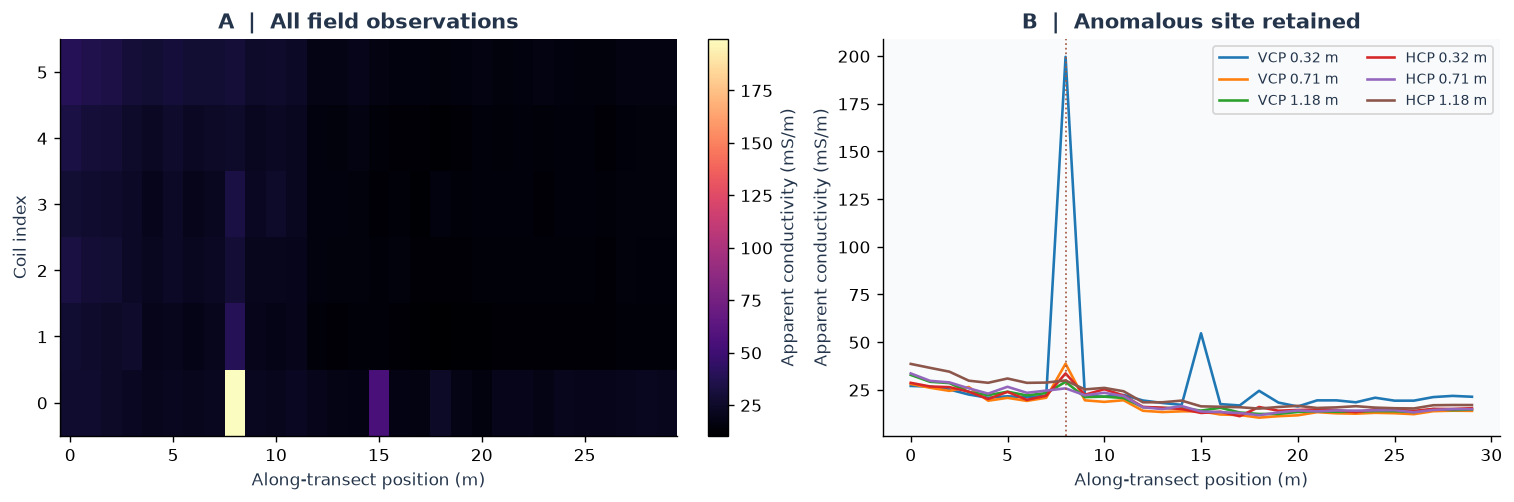

In [2]:
show('acquisition',viz.acquisition(data))

## 3. Physics and discrete identifiability

For depth z, spacing s and cumulative response C, the low-induction-number model is

$$C_{mathrm{HCP}}(z)=(1+4z^2/s^2)^{-1/2},\qquad C_{mathrm{VCP}}(z)=\sqrt{1+4z^2/s^2}-2z/s.$$

The response fraction below the ground is C(0)=1. A layer's contribution is the difference between its upper and lower cumulative response; the infinite bottom layer uses the limit C(infinity)=0. For conductivity vector sigma and observation vector a,

$$a=J\sigma+e,\qquad J_{ij}=C_i(d_j)-C_i(d_{j+1}).$$

Interfaces d are0,.25,.5,.75,1,1.5,2m and infinity; e contains measurement error and model discrepancy. Every row of J sums to one, preserving a uniform half-space's conductivity. Six observations cannot uniquely determine seven layer values. The singular values show further conditioning difficulties. No noise covariance is available, so residual RMS is reported without a statistical reduced-chi-square interpretation.

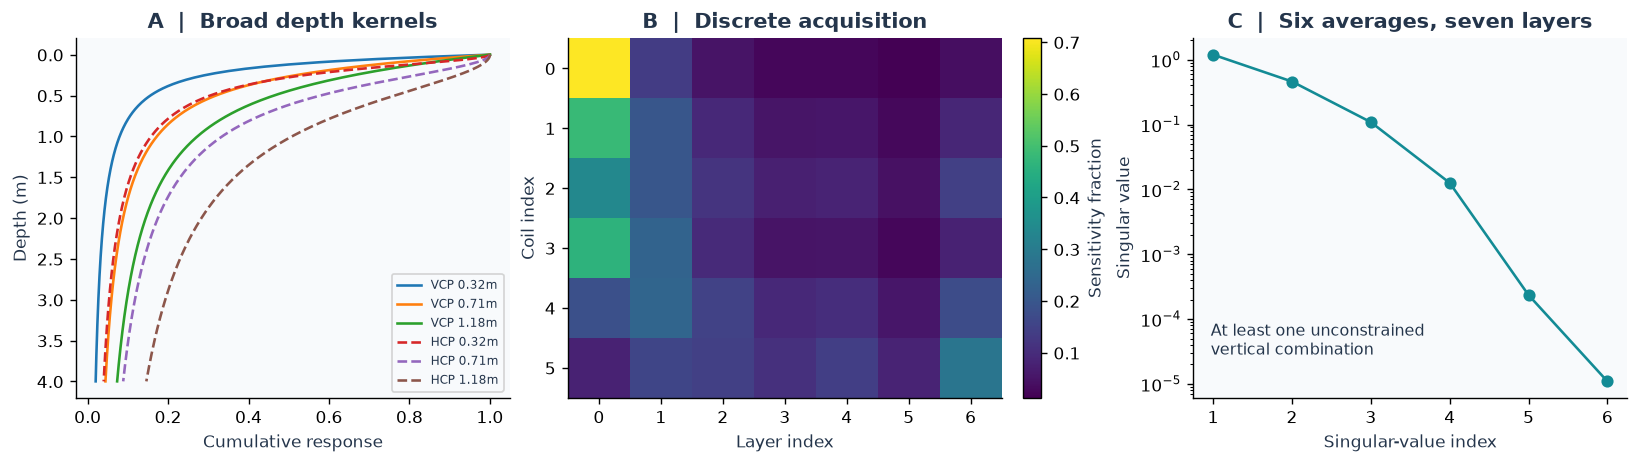

In [3]:
show('sensitivity',viz.sensitivity(data))

## 4. Implemented inverse and fresh reconstruction

The selected author method minimizes

$$F(\sigma)=\sqrt{\frac{\|J\sigma-a\|_2^2}{6}+\frac{\alpha}{7}\sum_{j=0}^{5}(\sigma_{j+1}-\sigma_j)^2},\qquad0\leq\sigma_j\leq300\ \mathrm{mS/m}.$$

Here alpha=.07 controls vertical smoothness. Every station starts with20mS/m in each layer. Local code explicitly evaluates the cumulative sensitivities, forward response, objective and adjacent differences; SciPy supplies the general L-BFGS-B optimizer, using ftol=1e-12,gtol=1e-8,maxiter=1000. There is no lateral regularization. The following cell computes the full bound reconstruction and writes its submission file. It never loads a cached result as a fresh reconstruction.

Fresh reconstruction seconds: 0.2687745000002906
Optimizer successes: 30 of 30
Conductivity range mS/m: 0.0 165.92179219613647


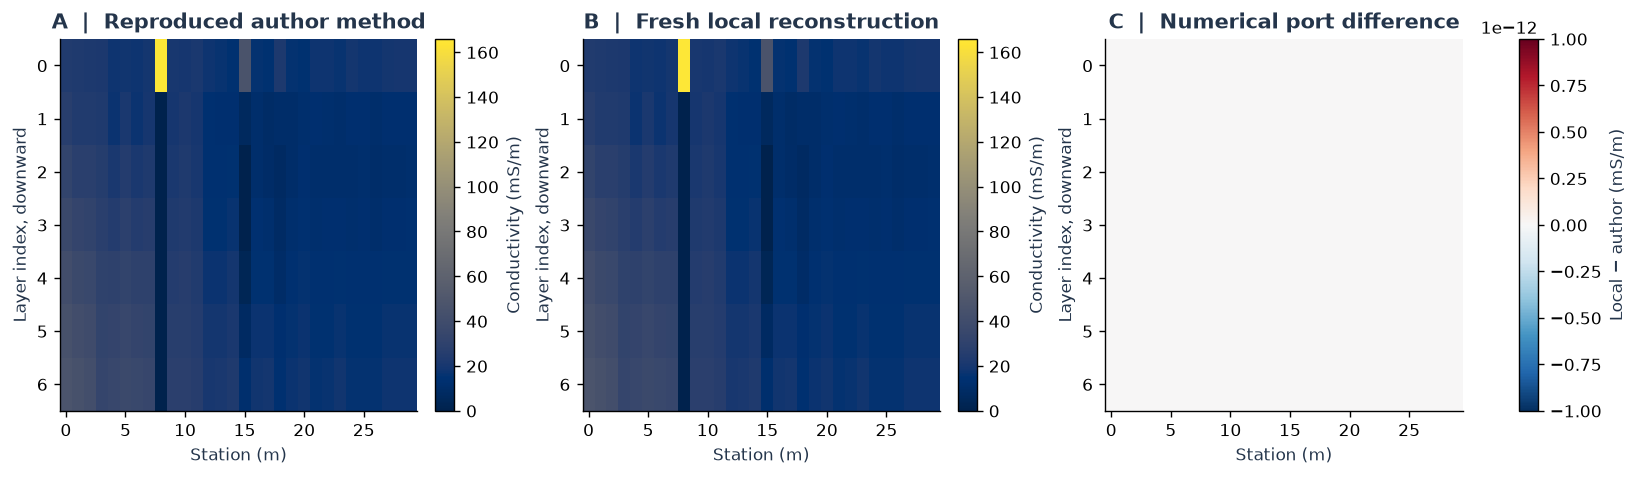

In [4]:
start=time.perf_counter()
fresh,diagnostics=reconstruct(data)
runtime=time.perf_counter()-start
(root/'output').mkdir(exist_ok=True)
np.savez_compressed(root/'output/reconstruction.npz',reconstruction=fresh[None])
print('Fresh reconstruction seconds:',runtime)
print('Optimizer successes:',sum(d['success'] for d in diagnostics),'of',len(diagnostics))
print('Conductivity range mS/m:',fresh.min(),fresh.max())
show('reconstruction',viz.reconstruction(data,fresh,author))

## 5. Scientific comparisons and sensitivity

First compare the fresh conductivity image against the independently reproduced author image, then project every station back into all six measurement channels. A strong residual at station8 indicates model inadequacy or an anomalous response. Numerical method agreement cannot resolve this physical limitation.

The author CSgn comparison uses a different penalty scaling and permits negative conductivities. The same-objective unbounded quadratic solution isolates the effect of positivity. These are distinct, actually computed comparisons rather than missing-method placeholders. Finally, a nine-value alpha sweep measures the tradeoff between forward fit and vertical roughness. These extra reconstructions use the same bound observations.

{
  "fresh_vs_reproduced_author_ncc": 1.0,
  "fresh_vs_reproduced_author_dynamic_range_nrmse": 0.0,
  "fresh_runtime_seconds": 0.2687745000002906,
  "optimizer_successes": 30
}


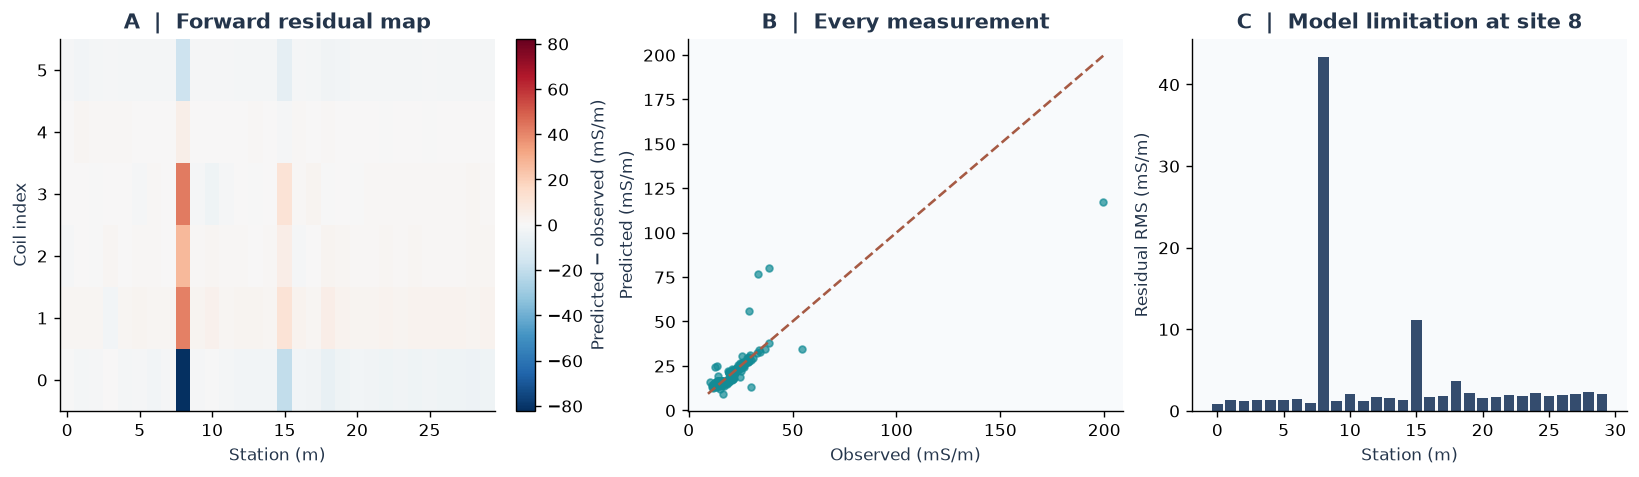

In [5]:
ncc,nrmse=viz.compare(fresh,author)
metrics={'fresh_vs_reproduced_author_ncc':ncc,'fresh_vs_reproduced_author_dynamic_range_nrmse':nrmse,'fresh_runtime_seconds':runtime,'optimizer_successes':sum(d['success'] for d in diagnostics)}
print(json.dumps(metrics,indent=2,allow_nan=False))
show('residuals',viz.residuals(data,fresh))

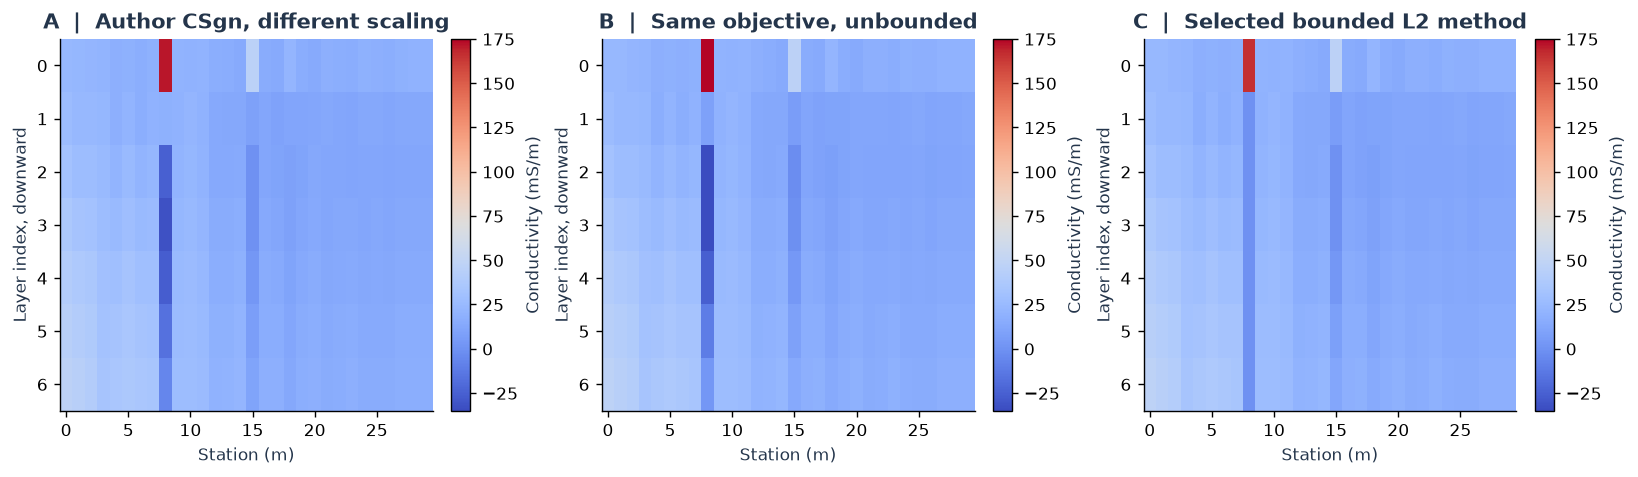

In [6]:
show('comparisons',viz.comparisons(data,fresh,gn))

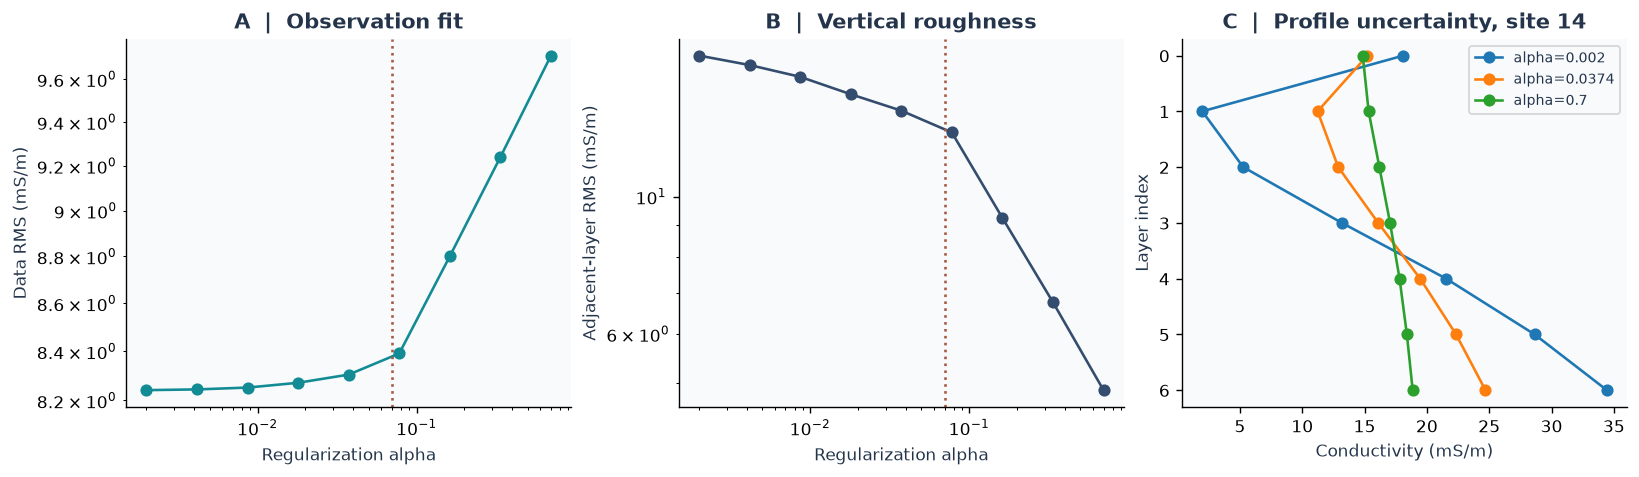

In [7]:
show('regularization',viz.regularization(data))

In [8]:
# Check the standalone Judge without importing its implementation into the solver.
import subprocess
run=subprocess.run([sys.executable,str(root/'evaluation/judge.py'),'--prediction',str(root/'output/reconstruction.npz'),'--report',str(root/'output/judge_report.json')],capture_output=True,text=True)
assert run.returncode==0,(run.stdout,run.stderr)
judge=json.loads((root/'output/judge_report.json').read_text())
print(json.dumps(judge,indent=2))

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc": 1.0000000000000002,
    "nrmse": 0.0
  },
  "thresholds": {
    "ncc": {
      "comparison": ">=",
      "boundary": 0.99999
    },
    "nrmse": {
      "comparison": "<=",
      "boundary": 0.0005
    }
  },
  "errors": []
}


## 6. What this section supports

The local extraction reproduces the selected bounded standard method while retaining the complete acquisition and its difficult station. Vertical smoothness stabilizes the inverse, and conductivity bounds prevent negative electrical properties. The reconstruction remains conditional on low induction number, local layering and the regularization choice. Station8's residual cannot be interpreted as known Gaussian noise. A field conductivity image produced under an approximate model is not an independently measured truth.

The comparison maps separate upstream measurements, fresh local measurements, the author CSgn alternative and the same-objective unconstrained solution. The regularization sweep illustrates uncertainty caused by unresolved depth combinations. See `test/validation.md` for exact revisions, hashes, tolerances and executed validation evidence.